# Aujourd'hui, c'est normal ?
## Exploration des températures historiques — Paris-Montsouris

### 1. Présentation du projet

Ce projet vise à concevoir une datavisualisation météorologique
interactive et animée, destinée au grand public.

Il comporte deux volets :
- Une carte météo de la France présentant les conditions
  météorologiques et les températures.
- Une rubrique « Aujourd'hui, c'est normal ? » permettant
  de comparer la température observée dans une station
  aux températures historiques relevées à la même date
  et à la même heure.

### 2. Objectifs de cette étude

- Explorer les archives horaires de Météo-France.
- Évaluer la disponibilité et la qualité des observations.
- Constituer une série historique fiable pour Paris-Montsouris.
- Calculer le classement d'une température récente.
- Identifier les trois températures historiques les plus élevées.
- Préparer les données pour une visualisation interactive D3.js.

### 3. Sources et périmètre

**Producteur :** Météo-France

**Source :** data.gouv.fr — Données climatologiques de base horaires

**Station pilote :** Paris-Montsouris (75114001)

**Période étudiée :** 1990–2026, selon les observations disponibles.

**Licence :** Licence Ouverte / Open Licence 2.0

**Méthode :** Python, Pandas et Jupyter Notebook.

Les heures des archives sont exprimées en UTC.

### 4. Précautions méthodologiques

Une comparaison historique à date et heure identiques
ne constitue pas à elle seule une normale climatologique.

Les observations manquantes, les codes qualité,
la continuité des séries et les conditions de comparaison
seront examinés avant le calcul des classements.

## 5. Chargement des données

Les observations horaires proviennent de cinq archives Météo-France
couvrant la période 1990–2026.

Les fichiers sont conservés au format CSV compressé (.csv.gz).
Nous utilisons Pandas pour les lire sans les décompresser.

Cette première étape vérifie la présence des cinq fichiers.

In [1]:
from pathlib import Path
import pandas as pd

# Le notebook se trouve dans meteo/notebooks/
DATA_DIR = Path.cwd().parent / "data"

fichiers = sorted(DATA_DIR.glob("*.csv.gz"))

print(f"Nombre d'archives trouvées : {len(fichiers)}")

for fichier in fichiers:
    print(f" - {fichier.name}")

assert len(fichiers) == 5, "Les cinq archives attendues sont introuvables."

Nombre d'archives trouvées : 5
 - H_75_1990-1999.csv.gz
 - H_75_2000-2009.csv.gz
 - H_75_2010-2019.csv.gz
 - H_75_latest-2025-2026.csv.gz
 - H_75_previous-2020-2024.csv.gz


## 6. Identification de la station Paris-Montsouris

Les fichiers Météo-France regroupent les observations de plusieurs
stations du département de Paris.

Nous sélectionnons la station Paris-Montsouris (75114001)
pour constituer une série historique homogène.

Cette étape permet de mesurer le nombre d'observations et
la disponibilité des températures pour chaque période.

In [2]:
STATION_ID = "75114001"

resultats = []

for fichier in fichiers:
    df = pd.read_csv(
        fichier,
        sep=";",
        compression="gzip",
        dtype={"NUM_POSTE": str},
        usecols=["NUM_POSTE", "AAAAMMJJHH", "T", "QT"]
    )

    paris = df[df["NUM_POSTE"] == STATION_ID]

    resultats.append({
        "Fichier": fichier.name,
        "Relevés": len(paris),
        "Températures disponibles": paris["T"].notna().sum(),
        "QT = 1": (paris["QT"] == 1).sum(),
        "QT = 9": (paris["QT"] == 9).sum()
    })

bilan = pd.DataFrame(resultats)

display(bilan)

,Fichier,Relevés,Températures disponibles,QT = 1,QT = 9
0,H_75_1990-1999.csv.gz,82690,72089,72089,0
1,H_75_2000-2009.csv.gz,87672,87655,87650,6
2,H_75_2010-2019.csv.gz,87648,87647,87647,0
3,H_75_latest-2025-2026.csv.gz,16350,16349,16339,10
4,H_75_previous-2020-2024.csv.gz,43848,43848,43848,0


## 7. Analyse de la disponibilité des températures

Nous examinons la proportion de températures disponibles pour
chaque année afin d'identifier les périodes incomplètes.

La disponibilité est calculée par rapport au nombre théorique
d'heures de chaque année, en tenant compte des années bissextiles.

Cette analyse permettra de définir la période historique
la plus adaptée à notre datavisualisation.

Text(36, 50, 'En cours')

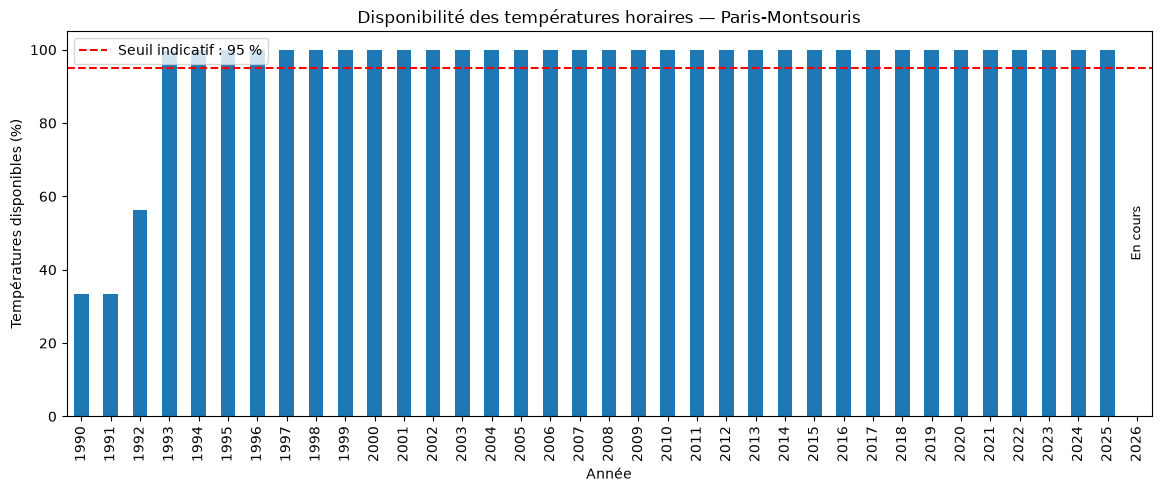

In [6]:
# Rassembler les observations de Paris-Montsouris
observations = []

for fichier in fichiers:
    df = pd.read_csv(
        fichier,
        sep=";",
        compression="gzip",
        dtype={"NUM_POSTE": str},
        usecols=["NUM_POSTE", "AAAAMMJJHH", "T", "QT"]
    )

    observations.append(
        df.loc[df["NUM_POSTE"] == STATION_ID].copy()
    )

meteo = pd.concat(observations, ignore_index=True)

# Convertir les dates UTC
meteo["date"] = pd.to_datetime(
    meteo["AAAAMMJJHH"].astype(str),
    format="%Y%m%d%H",
    utc=True
)

meteo["annee"] = meteo["date"].dt.year

# Nombre de températures renseignées par année
disponibilite = meteo.groupby("annee")["T"].count()

# Nombre théorique d'heures par année
heures_attendues = pd.Series(
    {
        annee: 8784 if pd.Timestamp(f"{annee}-01-01").is_leap_year else 8760
        for annee in disponibilite.index
    }
)

# La dernière année est en cours : on la distingue des années complètes
pourcentage = 100 * disponibilite / heures_attendues

annee_en_cours = meteo["annee"].max()
pourcentage.loc[annee_en_cours] = float("nan")

# Premier graphique exploratoire
ax = pourcentage.plot(
    kind="bar",
    figsize=(14, 5),
    title="Disponibilité des températures horaires — Paris-Montsouris",
    ylabel="Températures disponibles (%)",
    xlabel="Année",
    ylim=(0, 105)
)

ax.axhline(95, color="red", linestyle="--", label="Seuil indicatif : 95 %")
ax.legend()

ax.text(
    len(pourcentage) - 1,
    50,
    "En cours",
    rotation=90,
    ha="center",
    va="center",
    fontsize=9
)

### 7.1. Résultats et choix de la période historique

L'analyse de la disponibilité des températures horaires
de Paris-Montsouris met en évidence trois périodes :

- **1990–1992 :** couverture insuffisante pour constituer
  une référence historique complète.
- **1993–2025 :** disponibilité très élevée des températures
  horaires, permettant de constituer une série de 33 années.
- **2026 :** année en cours, traitée séparément afin de ne pas
  confondre absence de données futures et données manquantes.

**Décision méthodologique :**

La période 1993–2025 est retenue comme base historique
provisoire pour les comparaisons de températures.

Les observations de 2026 seront comparées à cette période,
à date et heure identiques.

Avant le calcul définitif des classements, nous vérifierons
les codes qualité, les doublons et la disponibilité des
observations pour chaque date et heure comparées.

Cette comparaison constitue un classement empirique des
observations historiques et non une normale climatologique
officielle.